# Практическая работа №1

## Постановка задачи

Тема: "Поиск ассоциативных правил"  
Выполнил: Алиев Эльчин Алойсатович
Группа: КИ24-17/1б

Цель: знакомство с методами поиска ассоциативных правил, формирование навыков выполнения поиска ассоциативных правил на языке Python

Задачи:  
1. Подготовка исходных данных
2. Генерация частных наборов данных
3. Генерация ассоциативных правил


## Предобработка данных

Импорт необходимых библиотек

In [1]:
import inspect
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

In [2]:
dataset = pd.read_csv('rules_dataset.csv')

In [3]:
dataset

,Member_number,Date,itemDescription
0,1808,21-07-2015,tropical fruit
1,2552,05-01-2015,whole milk
2,2300,19-09-2015,pip fruit
3,1187,12-12-2015,other vegetables
4,3037,01-02-2015,whole milk
...,...,...,...
38760,4471,08-10-2014,sliced cheese
38761,2022,23-02-2014,candy
38762,1097,16-04-2014,cake bar
38763,1510,03-12-2014,fruit/vegetable juice


In [4]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38765 entries, 0 to 38764
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Member_number    38765 non-null  int64 
 1   Date             38765 non-null  object
 2   itemDescription  38765 non-null  object
dtypes: int64(1), object(2)
memory usage: 908.7+ KB


In [5]:
dataset.isna().sum()

Member_number      0
Date               0
itemDescription    0
dtype: int64

Данные в формате: покупатель-дата-покупка, нам необходима треться колонка. Пропущенные значения отсутствуют.

In [6]:
dataset['itemDescription'].value_counts()

itemDescription
whole milk               2502
other vegetables         1898
rolls/buns               1716
soda                     1514
yogurt                   1334
                         ... 
rubbing alcohol             5
bags                        4
baby cosmetics              3
kitchen utensil             1
preservation products       1
Name: count, Length: 167, dtype: int64

Наблюдается большое разнообразие видов транзакций

### Представление данных в виде транзакций

In [7]:
MIN_SUPPORT = 0.005
MIN_CONFIDENCE = 0.05
MIN_LIFT = 1.00
MIN_CONVICTION = 1.00
MIN_LEVERAGE = 0.00

In [8]:
transactions = (
    dataset.groupby(['Member_number', 'Date'])['itemDescription']
    .apply(lambda s: list(set(s)))
    .tolist()
)
te = TransactionEncoder()
te_array = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_array, columns=te.columns_)

In [9]:
df

,Instant food products,UHT-milk,abrasive cleaner,artif. sweetener,baby cosmetics,bags,baking powder,bathroom cleaner,beef,berries,...,turkey,vinegar,waffles,whipped/sour cream,whisky,white bread,white wine,whole milk,yogurt,zwieback
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,True,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14958,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,True,False
14959,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14960,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
14961,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## Генерация наборов и правил

С помощью встроенного метода apriori найдем частые наборы

In [10]:
def itemset_str(itemset):
    """
    Функция для открытия и закрытия списка товаров
    """
    return "{" + ", ".join(sorted(itemset)) + "}"

frequent_itemsets_apriori = apriori(
    df,
    min_support=MIN_SUPPORT, 
    use_colnames=True
).copy()
frequent_itemsets_apriori["length"] = frequent_itemsets_apriori["itemsets"].apply(len)
frequent_itemsets_apriori["freq"] = (
    frequent_itemsets_apriori["support"] * len(df)
).round().astype(int)
frequent_itemsets_apriori["itemsets_text"] = (
    frequent_itemsets_apriori["itemsets"].apply(itemset_str)
)
frequent_itemsets_apriori = frequent_itemsets_apriori.sort_values(
    ["length", "support", "itemsets_text"],
    ascending=[True, False, True]
).reset_index(drop=True)

frequent_itemsets_apriori[
    ["length", "itemsets_text", "freq", "support"]
]


,length,itemsets_text,freq,support
0,1,{whole milk},2363,0.157923
1,1,{other vegetables},1827,0.122101
2,1,{rolls/buns},1646,0.110005
3,1,{soda},1453,0.097106
4,1,{yogurt},1285,0.085879
...,...,...,...,...
121,2,"{other vegetables, root vegetables}",79,0.005280
122,2,"{root vegetables, soda}",79,0.005280
123,2,"{tropical fruit, yogurt}",78,0.005213
124,2,"{frankfurter, other vegetables}",77,0.005146


In [11]:
for k in sorted(frequent_itemsets_apriori["length"].unique()):
    print(f"L{k}")
    display(
        frequent_itemsets_apriori.loc[
            frequent_itemsets_apriori["length"] == k,
            ["itemsets_text", "freq", "support"]
        ].reset_index(drop=True)
    )

L1


,itemsets_text,freq,support
0,{whole milk},2363,0.157923
1,{other vegetables},1827,0.122101
2,{rolls/buns},1646,0.110005
3,{soda},1453,0.097106
4,{yogurt},1285,0.085879
...,...,...,...
84,{canned vegetables},82,0.005480
85,{roll products },82,0.005480
86,{turkey},80,0.005347
87,{photo/film},79,0.005280


L2


,itemsets_text,freq,support
0,"{other vegetables, whole milk}",222,0.014837
1,"{rolls/buns, whole milk}",209,0.013968
2,"{soda, whole milk}",174,0.011629
3,"{whole milk, yogurt}",167,0.011161
4,"{other vegetables, rolls/buns}",158,0.010559
5,"{other vegetables, soda}",145,0.009691
6,"{sausage, whole milk}",134,0.008955
7,"{tropical fruit, whole milk}",123,0.008220
8,"{other vegetables, yogurt}",121,0.008087
9,"{rolls/buns, soda}",121,0.008087


Проделываем то же самое, что и в предыдущей ячейке, но методом fp-growth

In [12]:
frequent_itemsets_fp = fpgrowth(
    df,
    min_support=MIN_SUPPORT,
    use_colnames=True
).copy()

frequent_itemsets_fp["length"] = frequent_itemsets_fp["itemsets"].apply(len)
frequent_itemsets_fp["freq"] = (
    frequent_itemsets_fp["support"] * len(df)
).round().astype(int)
frequent_itemsets_fp["itemsets_text"] = (
    frequent_itemsets_fp["itemsets"].apply(itemset_str)
)

frequent_itemsets_fp = frequent_itemsets_fp.sort_values(
    ["length", "support", "itemsets_text"],
    ascending=[True, False, True]
).reset_index(drop=True)

frequent_itemsets_fp[
    ["length", "itemsets_text", "freq", "support"]
]


,length,itemsets_text,freq,support
0,1,{whole milk},2363,0.157923
1,1,{other vegetables},1827,0.122101
2,1,{rolls/buns},1646,0.110005
3,1,{soda},1453,0.097106
4,1,{yogurt},1285,0.085879
...,...,...,...,...
121,2,"{other vegetables, root vegetables}",79,0.005280
122,2,"{root vegetables, soda}",79,0.005280
123,2,"{tropical fruit, yogurt}",78,0.005213
124,2,"{frankfurter, other vegetables}",77,0.005146


Проверим, одинаковые ли наборы у данных методов

In [13]:
def normalize_itemsets(frame):
    return {
        frozenset(row.itemsets): float(row.support)
        for row in frame[["itemsets", "support"]].itertuples(index=False)
    }

apriori_result = normalize_itemsets(frequent_itemsets_apriori)
fp_result = normalize_itemsets(frequent_itemsets_fp)

same_itemsets = set(apriori_result) == set(fp_result)
same_supports = all(
    np.isclose(apriori_result[itemset], fp_result[itemset])
    for itemset in apriori_result.keys() & fp_result.keys()
)

comparison_algorithms = pd.DataFrame([
    {
        "Алгоритм": "Apriori",
        "Количество частых наборов": len(frequent_itemsets_apriori),
        "Генерирует кандидаты Ck": "Да",
        "Основная структура": "Ck и Lk",
    },
    {
        "Алгоритм": "FP-Growth",
        "Количество частых наборов": len(frequent_itemsets_fp),
        "Генерирует кандидаты Ck": "Нет",
        "Основная структура": "FP-tree",
    },
])

display(comparison_algorithms)

print("Одинаковые наборы:", same_itemsets)
print("Одинаковые support:", same_supports)


,Алгоритм,Количество частых наборов,Генерирует кандидаты Ck,Основная структура
0,Apriori,126,Да,Ck и Lk
1,FP-Growth,126,Нет,FP-tree


Одинаковые наборы: True
Одинаковые support: True


In [14]:
association_kwargs = {
    "metric": "support",
    "min_threshold": 0.0,
}
if "num_itemsets" in inspect.signature(association_rules).parameters:
    association_kwargs["num_itemsets"] = len(df)
rules = association_rules(
    frequent_itemsets_apriori[["support", "itemsets"]],
    **association_kwargs
).copy()

rules["impr"] = rules["lift"]
rules["antecedents_text"] = rules["antecedents"].apply(itemset_str)
rules["consequents_text"] = rules["consequents"].apply(itemset_str)
base_columns = [
    "antecedents_text",
    "consequents_text",
    "support",
    "confidence",
    "lift",
    "leverage",
    "conviction",
]
rules[
    base_columns
].sort_values(
    ["lift", "confidence"],
    ascending=False
).reset_index(drop=True)


,antecedents_text,consequents_text,support,confidence,lift,leverage,conviction
0,{frankfurter},{other vegetables},0.005146,0.136283,1.116150,0.000536,1.016420
1,{other vegetables},{frankfurter},0.005146,0.042146,1.116150,0.000536,1.004579
2,{sausage},{yogurt},0.005748,0.095238,1.108986,0.000565,1.010345
3,{yogurt},{sausage},0.005748,0.066926,1.108986,0.000565,1.007049
4,{sausage},{soda},0.005948,0.098560,1.014975,0.000088,1.001613
...,...,...,...,...,...,...,...
69,{soda},{yogurt},0.005814,0.059876,0.697219,-0.002525,0.972342
70,{root vegetables},{whole milk},0.007552,0.108549,0.687357,-0.003435,0.944615
71,{whole milk},{root vegetables},0.007552,0.047821,0.687357,-0.003435,0.977157
72,{root vegetables},{other vegetables},0.005280,0.075889,0.621522,-0.003215,0.949992


В результате генерации ассоциативных правил получены оценки ключевых метрик для выявленных пар товаров. Значения поддержки лежат в диапазоне от 0.5% до 1.5%.  Оценка меры Lift позволила разделить полученные ассоциации на две группы: часть правил обладает положительной статистической зависимостью с Lift выше единицы (до 1.116), где появление одного продукта увеличивает вероятность приобретения другого более чем на 11% относительно случайного выбора, в то время как правила с Lift ниже 1 (в частности, многие связки с молоком) показывают отрицательную связь, так как базовые товары покупаются часто сами по себе независимо от остальных позиций. Положительные значения показателя Leverage для сильных правил подтверждают неслучайный перевес совместной частоты над произведением независимых вероятностей, а мера Conviction превышает единицу, свидетельствуя о том, что данные правила ошибаются реже, чем простое случайное угадывание следствия

### Фильтрация метрик

In [18]:
rules_basic = rules[
    (rules["support"] >= MIN_SUPPORT)
    & (rules["confidence"] >= MIN_CONFIDENCE)
    & (rules["lift"] > MIN_LIFT)
    & (rules["conviction"] > MIN_CONVICTION)
    & (rules["leverage"] > MIN_LEVERAGE)
].copy()

rules_basic[
    [
        "antecedents_text",
        "consequents_text",
        "support",
        "confidence",
        "lift",
        "leverage",
        "conviction",
    ]
].sort_values(
    ["lift", "confidence"],
    ascending=False
).reset_index(drop=True)


,antecedents_text,consequents_text,support,confidence,lift,leverage,conviction
0,{frankfurter},{other vegetables},0.005146,0.136283,1.116150,0.000536,1.016420
1,{sausage},{yogurt},0.005748,0.095238,1.108986,0.000565,1.010345
2,{yogurt},{sausage},0.005748,0.066926,1.108986,0.000565,1.007049
3,{sausage},{soda},0.005948,0.098560,1.014975,0.000088,1.001613
4,{soda},{sausage},0.005948,0.061253,1.014975,0.000088,1.000963


Применение фильтрации по пороговым значениям позволило отсеять псевдозакономерности и выделить пять качественных ассоциативных правил, обладающих положительной статистической связью. В выборку вошли взаимные связки сосисок и колбасных изделий с другими категориями: франкфуртеры с овощами, сосиски с йогуртом и сосиски с газированной водой

### Исследование влияние величины пороговых значений

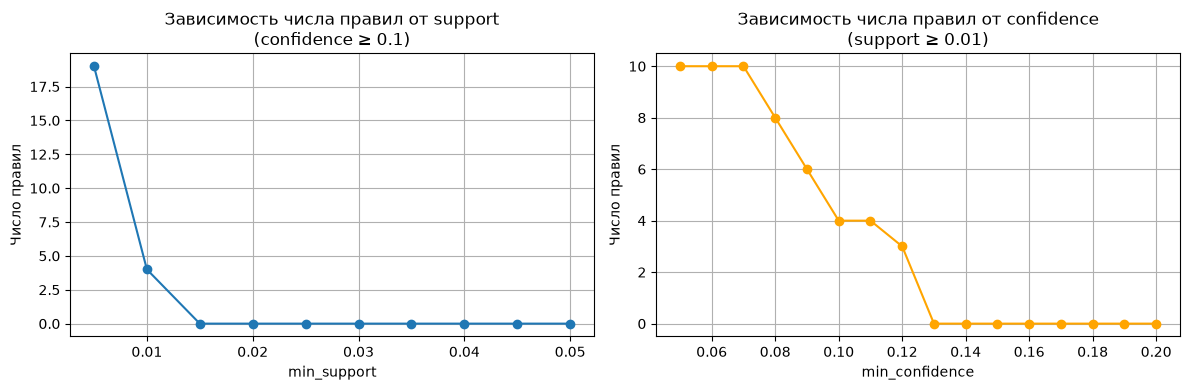

In [16]:
support_range = np.arange(0.005, 0.055, 0.005)
confidence_range = np.arange(0.05, 0.20, 0.01)
counts_support = []
counts_conf = []
fixed_conf = 0.1
for sup in support_range:
    freq = apriori(df, min_support=sup, use_colnames=True)
    if len(freq) == 0:
        counts_support.append(0)
        continue
    temp_rules = association_rules(freq, metric="confidence", min_threshold=fixed_conf)
    counts_support.append(len(temp_rules))
fixed_sup = 0.01
freq_fixed = apriori(df, min_support=fixed_sup, use_colnames=True)
for conf in confidence_range:
    if len(freq_fixed) == 0:
        counts_conf.append(0)
        continue
    temp_rules = association_rules(freq_fixed, metric="confidence", min_threshold=conf)
    counts_conf.append(len(temp_rules))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(support_range, counts_support, marker='o')
axes[0].set_xlabel('min_support')
axes[0].set_ylabel('Число правил')
axes[0].set_title(f'Зависимость числа правил от support\n(confidence ≥ {fixed_conf})')
axes[0].grid(True)

axes[1].plot(confidence_range, counts_conf, marker='o', color='orange')
axes[1].set_xlabel('min_confidence')
axes[1].set_ylabel('Число правил')
axes[1].set_title(f'Зависимость числа правил от confidence\n(support ≥ {fixed_sup})')
axes[1].grid(True)

plt.tight_layout()
plt.show()

Зависимость числа правил от минимальной поддержки имеет ярко выраженный ступенчатый убывающий характер, что подтверждает свойство антимонотонности Apriori: по мере роста порога поддержки выше 1.5% число частых наборов и правил стремительно падает до нуля. График зависимости от минимальной достоверности показывает плавное снижение количества правил от десяти при пороге 7% до нуля при пороге выше 13%.

### Визуализация полученных правил

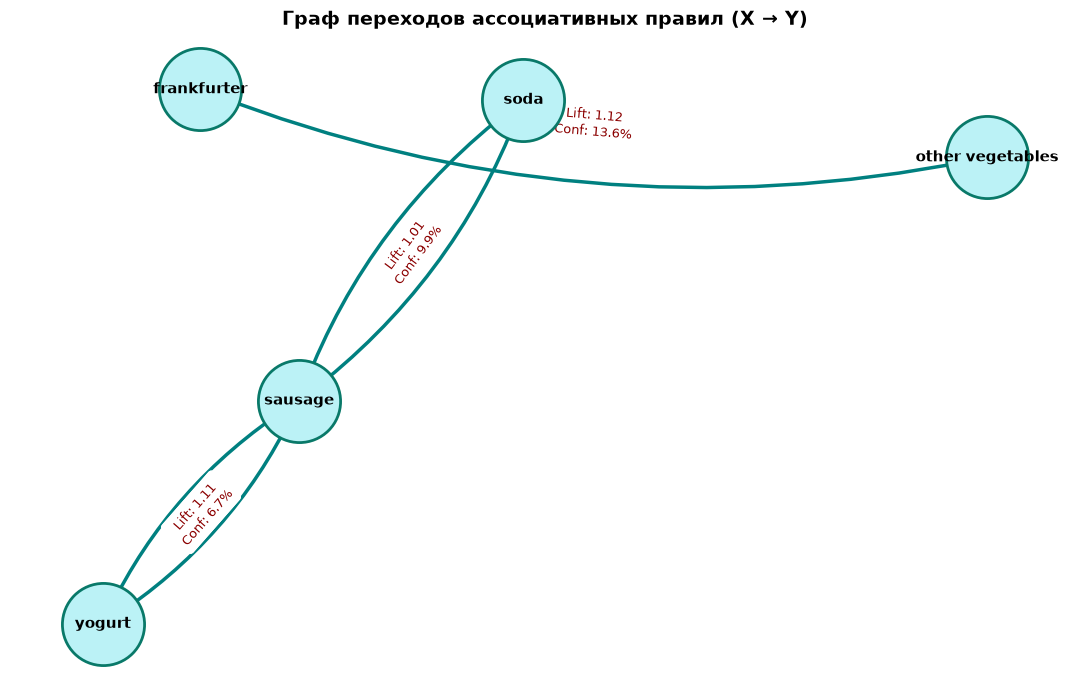

In [17]:
import networkx as nx
G = nx.DiGraph()
for _, row in rules_basic.iterrows():
    ant = row['antecedents_text'].strip('{}')
    con = row['consequents_text'].strip('{}')
    G.add_edge(
        ant, 
        con, 
        weight=row['lift'], 
        confidence=row['confidence'],
        support=row['support']
    )

plt.figure(figsize=(11, 7))
pos = nx.spring_layout(G, k=1.5, seed=42)  
nx.draw_networkx_nodes(
    G, pos, 
    node_size=3500, 
    node_color='#bbf2f6', 
    edgecolors='#097969', 
    linewidths=2
)
nx.draw_networkx_labels(
    G, pos, 
    font_size=11, 
    font_weight='bold', 
    font_family='sans-serif'
)
nx.draw_networkx_edges(
    G, pos, 
    arrowstyle='-|>', 
    arrowsize=25, 
    edge_color='teal', 
    width=2.5, 
    connectionstyle='arc3,rad=0.15'
)
edge_labels = {
    (u, v): f"Lift: {d['weight']:.2f}\nConf: {d['confidence']*100:.1f}%" 
    for u, v, d in G.edges(data=True)
}
nx.draw_networkx_edge_labels(
    G, pos, 
    edge_labels=edge_labels, 
    font_size=9, 
    font_color='darkred'
)

plt.title('Граф переходов ассоциативных правил (X → Y)', fontsize=14, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()


Визуализация в виде ориентированного графа переходов наглядно отражает структуру и направление выявленных ассоциативных связей. Центральным узлом продуктовой сети выступает категория мясных изделий и сосисок, от которой исходят и к которой сходятся направленные ребра с сопутствующими товарами — овощами, йогуртами и напитками. Наибольшую силу связи демонстрирует переход от покупки франкфуртеров к овощам, а также устойчивые двусторонние переходы между сосисками и газировкой или йогуртом. С точки зрения бизнес-логики такие данные позволяют проектировать эффективную кросс-выкладку: размещение соусов, напитков и готовых овощных наборов рядом с мясной гастрономией стимулирует импульсивные покупки, а введение пакетированных предложений и скидочных купонов на сопутствующую корзину способствует увеличению среднего чека супермаркета.

## Выводы по работе

В ходе практической работы были освоены методы интеллектуального анализа рыночной корзины и генерации ассоциативных правил на языке Python. Из исходного массива чеков супермаркета путем группировки по идентификатору покупателя и дате было сформировано около 15 тысяч уникальных покупательских транзакций, закодированных в бинарную матрицу. Алгоритмы Apriori и FP-Growth при одинаковом пороге поддержки сгенерировали абсолютно идентичный набор из 126 частых элементов, подтвердив математическую эквивалентность результатов обоих методов. Визуализация полученных связей в виде графа переходов предоставила готовую основу для оптимизации выкладки товаров и планирования маркетинговых кросс-акций